# ITCS 6169/8169 — Computer Vision
## Assignment 2: Self-Supervised Visual Representation Learning

---

Assignment 1 asked you to train a supervised CNN on a small, 2,400-image, 16-class scene dataset. This assignment asks a different question:

**Can we learn better visual representations from the same limited dataset using self-supervised learning (SSL), without relying solely on class labels?**

This notebook is forked from the Assignment 1 starter/your Assignment 1 implementation, with everything that depended on pretrained weights removed and replaced with the SSL workflow. At minimum your report must compare: (1) a supervised baseline, (2) an SSL approach followed by fine-tuning, (3) your best recipe (which may be SSL pretraining, joint SSL+supervised training, stronger augmentation, or another justified strategy).

### Important rule: no external pretraining
- **Allowed:** randomly initialized CNNs/ViTs/other architectures, SSL pretraining using only the provided training images, joint supervised+SSL optimization, standard augmentation/regularization.
- **Not allowed:** ImageNet-pretrained CNNs/ViTs, CLIP/DINO/DINOv2/MAE/SAM or other foundation models with externally pretrained weights, additional images or external datasets.
- You may implement an architecture *inspired by* a pretrained/foundation model, but its weights must be randomly initialized and trained only on the provided data.

### Workflow
This notebook is built to be extended iteratively, the same way Assignment 1 was: get the supervised baseline and one SSL method working first, record the numbers, then add the next SSL approach (MoCo, joint SSL+supervised, DINO/MAE) as new sections below, comparing each against the baseline before moving on.

In [1]:
import sys
import torch
import torchvision

print("=== Environment Check ===")
print(f"Python version:     {sys.version}")
print(f"PyTorch version:    {torch.__version__}")
print(f"Torchvision version:{torchvision.__version__}")
print(f"CUDA available:     {torch.cuda.is_available()}")
print(f"PyTorch built with CUDA: {torch.version.cuda}")

if torch.cuda.is_available():
    print(f"GPU device:         {torch.cuda.get_device_name(0)}")
    print(f"GPU count:          {torch.cuda.device_count()}")
    print(f"CUDA capability:    {torch.cuda.get_device_capability(0)}")
    print(f"Total GPU memory:   {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
else:
    print("WARNING: CUDA not available — training will run on CPU (much slower).")
    print("Check: correct PyTorch build installed? NVIDIA driver installed? GPU recognized by OS?")

=== Environment Check ===
Python version:     3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
PyTorch version:    2.12.0.dev20260408+cu128
Torchvision version:0.27.0.dev20260407+cu128
CUDA available:     True
PyTorch built with CUDA: 12.8
GPU device:         NVIDIA GeForce RTX 5060 Laptop GPU
GPU count:          1
CUDA capability:    (12, 0)
Total GPU memory:   8.55 GB


In [2]:
from pathlib import Path
import random
import time
import copy

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, random_split
from torchvision import datasets, models, transforms
from torchvision.transforms import v2

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

PyTorch version: 2.12.0.dev20260408+cu128
CUDA available: True


In [3]:
# Optional: mount Google Drive when running in Colab.
# Skip this cell if you are running locally or on another server.
try:
    from google.colab import drive
    drive.mount('/content/gdrive')
except ImportError:
    print("Not running in Google Colab; Drive mount skipped.")

Not running in Google Colab; Drive mount skipped.


## 1. Set your working directory

Same dataset layout as Assignment 1:

```text
data/
  train/
    class_1/
    ...
  test/
    class_1/
    ...
```

Update `PROJECT_ROOT` below if your layout differs. **Do not hard-code a TA/instructor solution path.**

In [4]:
# CHANGE THIS PATH to your own assignment directory if needed.
PROJECT_ROOT = Path('.')
DATA_ROOT = PROJECT_ROOT / 'data'
TRAIN_ROOT = DATA_ROOT / 'train'
TEST_ROOT = DATA_ROOT / 'test'

print('Project root:', PROJECT_ROOT.resolve())
print('Training data:', TRAIN_ROOT)
print('Testing data:', TEST_ROOT)

Project root: C:\Users\omcka\Downloads\CV\Assignment 2
Training data: data\train
Testing data: data\test


In [5]:
# Sanity check: confirm both splits are present and have the same class folders.
# (This directly guards against the Assignment-1 Mountain-folder mismatch bug.)
import os
for folder, path in [('train', TRAIN_ROOT), ('test', TEST_ROOT)]:
    if path.exists():
        subdirs = sorted(d.name for d in path.iterdir() if d.is_dir())
        print(f"{folder}: {len(subdirs)} subfolders -> {subdirs}")
    else:
        print(f"{folder}: NOT FOUND")

train: 16 subfolders -> ['Bedroom', 'Coast', 'Flower', 'Forest', 'Highway', 'Industrial', 'InsideCity', 'Kitchen', 'LivingRoom', 'Mountain', 'Office', 'OpenCountry', 'Store', 'Street', 'Suburb', 'TallBuilding']
test: 16 subfolders -> ['Bedroom', 'Coast', 'Flower', 'Forest', 'Highway', 'Industrial', 'InsideCity', 'Kitchen', 'LivingRoom', 'Mountain', 'Office', 'OpenCountry', 'Store', 'Street', 'Suburb', 'TallBuilding']


## 2. Reproducibility and device

In [6]:
SEED = 0

def set_random_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_random_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

Using device: cuda


## 3. Data loading and augmentation

RGB, 224x224, straight away this time — there is no reason to replicate Assignment 1's deliberately-weak grayscale 64x64 starter transform here, since every architecture in this notebook trains from scratch regardless.

`NORM_MEAN`/`NORM_STD` below are just fixed normalization constants (the ImageNet mean/std convention). Using them is **not** the same as using pretrained weights — nothing in the assignment's rules bans a normalization convention. If you want to be fully independent of any ImageNet-derived number, swap these for the mean/std computed from your own 2,400 training images instead.

In [7]:
IMG_SIZE = 224
BATCH_SIZE = 32
VAL_FRACTION = 0.20
NUM_WORKERS = 4

NORM_MEAN = [0.485, 0.456, 0.406]
NORM_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=NORM_MEAN, std=NORM_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=NORM_MEAN, std=NORM_STD),
])

full_train_dataset_aug = datasets.ImageFolder(TRAIN_ROOT, transform=train_transform)
full_train_dataset_eval = datasets.ImageFolder(TRAIN_ROOT, transform=eval_transform)
test_dataset = datasets.ImageFolder(TEST_ROOT, transform=eval_transform)

class_names = full_train_dataset_aug.classes
num_classes = len(class_names)
print(f'Classes ({num_classes}): {class_names}')
print(f'Total training images: {len(full_train_dataset_aug)}')
print(f'Test images: {len(test_dataset)}')

val_size = int(round(len(full_train_dataset_aug) * VAL_FRACTION))
train_size = len(full_train_dataset_aug) - val_size
generator = torch.Generator().manual_seed(SEED)
train_subset, val_subset = random_split(
    full_train_dataset_aug, [train_size, val_size], generator=generator
)
# Re-wrap the val subset so it uses eval_transform, not train_transform.
val_subset = torch.utils.data.Subset(full_train_dataset_eval, val_subset.indices)

pin_memory = torch.cuda.is_available()
train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True,
                           num_workers=NUM_WORKERS, pin_memory=pin_memory)
val_loader = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=pin_memory)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=pin_memory)

print(f'Train: {len(train_subset)} | Validation: {len(val_subset)} | Test: {len(test_dataset)}')

Classes (16): ['Bedroom', 'Coast', 'Flower', 'Forest', 'Highway', 'Industrial', 'InsideCity', 'Kitchen', 'LivingRoom', 'Mountain', 'Office', 'OpenCountry', 'Store', 'Street', 'Suburb', 'TallBuilding']
Total training images: 2256
Test images: 400
Train: 1805 | Validation: 451 | Test: 400


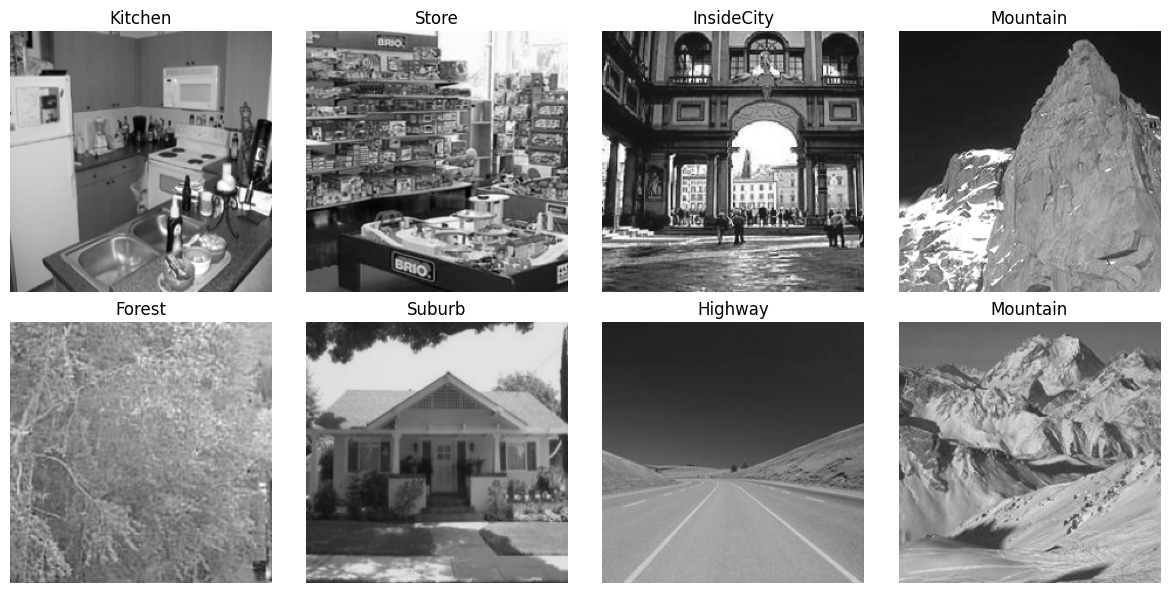

In [8]:
# Visualize a few training examples (RGB, so un-normalize with NORM_MEAN/STD).
images, labels = next(iter(train_loader))
mean_t = torch.tensor(NORM_MEAN).view(3, 1, 1)
std_t = torch.tensor(NORM_STD).view(3, 1, 1)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, image, label in zip(axes.flat, images[:8], labels[:8]):
    image = (image * std_t + mean_t).clamp(0, 1)
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(class_names[label.item()])
    ax.axis('off')
plt.tight_layout()
plt.show()

## 4. Model, training, and evaluation utilities

`build_resnet18` is the one change that actually matters versus Assignment 1: `weights=None` instead of `ResNet18_Weights.IMAGENET1K_V1`. Everything downstream (two-phase fine-tuning, warm-starting from a pretrained checkpoint) that existed specifically to protect pretrained early layers has been removed, since there is nothing pretrained to protect anymore — every model here starts from a genuinely random init.

In [9]:
def build_resnet18(num_classes, dropout_rate=0.0):
    """Randomly initialized ResNet18 -- no pretrained weights (assignment requires this)."""
    model = models.resnet18(weights=None)
    in_features = model.fc.in_features
    if dropout_rate > 0:
        model.fc = nn.Sequential(nn.Dropout(dropout_rate), nn.Linear(in_features, num_classes))
    else:
        model.fc = nn.Linear(in_features, num_classes)
    return model


@torch.inference_mode()
def evaluate(model, loader, device):
    model.eval()
    criterion = nn.CrossEntropyLoss()
    correct, total, running_loss = 0, 0, 0.0
    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        logits = model(images)
        loss = criterion(logits, labels)
        running_loss += loss.item() * images.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total


def train_model(model, train_loader, val_loader, optimizer, scheduler=None,
                 epochs=70, patience=10, label_smoothing=0.0,
                 use_mixup_cutmix=False, mixup_cutmix_alpha=1.0,
                 num_classes=num_classes, phase_name='train', device=device):
    criterion = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    model = model.to(device)

    cutmix_or_mixup = None
    if use_mixup_cutmix:
        cutmix = v2.CutMix(num_classes=num_classes, alpha=mixup_cutmix_alpha)
        mixup = v2.MixUp(num_classes=num_classes, alpha=mixup_cutmix_alpha)
        cutmix_or_mixup = v2.RandomChoice([cutmix, mixup])

    best_state = copy.deepcopy(model.state_dict())
    best_val_acc = 0.0
    epochs_no_improve = 0
    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    start = time.time()

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss, total_seen = 0.0, 0
        for images, labels in train_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            if cutmix_or_mixup is not None:
                images, labels = cutmix_or_mixup(images, labels)

            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * images.size(0)
            total_seen += images.size(0)

        if scheduler is not None:
            scheduler.step()

        train_loss = total_loss / total_seen
        val_loss, val_acc = evaluate(model, val_loader, device)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = copy.deepcopy(model.state_dict())
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1

        elapsed = time.time() - start
        current_lr = optimizer.param_groups[0]['lr']
        print(f'[{phase_name}] Epoch {epoch:03d}/{epochs} | train loss {train_loss:.4f} | '
              f'val loss {val_loss:.4f} | val acc {val_acc:.4f} | lr {current_lr:.6f} | {elapsed:.1f}s')

        if epochs_no_improve >= patience:
            print(f'[{phase_name}] Early stopping after {epoch} epochs (no improvement for {patience} epochs).')
            break

    model.load_state_dict(best_state)
    print(f'[{phase_name}] Best validation accuracy: {best_val_acc:.4f}')
    return model, history

## 5. Supervised baseline (random-init ResNet18, classification objective only)

This is Required Experiment #1 from the assignment: no SSL, just supervised training from scratch. Expect this number to land below Assignment 1's pretrained-ResNet18 result -- that gap *is* the thing this assignment is asking you to try to close with SSL.

In [10]:
set_random_seed(SEED)

model_baseline = build_resnet18(num_classes=num_classes, dropout_rate=0.3)
optimizer_baseline = optim.SGD(model_baseline.parameters(), lr=0.01, momentum=0.9, weight_decay=1e-4)

BASELINE_EPOCHS = 150  # from-scratch training typically needs more epochs than fine-tuning -- probe this
scheduler_baseline = optim.lr_scheduler.CosineAnnealingLR(optimizer_baseline, T_max=BASELINE_EPOCHS)

model_baseline, history_baseline = train_model(
    model_baseline, train_loader, val_loader, optimizer_baseline, scheduler_baseline,
    epochs=BASELINE_EPOCHS, patience=15, label_smoothing=0.1,
    use_mixup_cutmix=True, mixup_cutmix_alpha=1.0, phase_name='baseline', device=device
)

[baseline] Epoch 001/150 | train loss 2.8407 | val loss 2.6662 | val acc 0.1907 | lr 0.009999 | 42.4s
[baseline] Epoch 002/150 | train loss 2.6147 | val loss 2.1137 | val acc 0.3038 | lr 0.009996 | 82.5s
[baseline] Epoch 003/150 | train loss 2.5366 | val loss 2.3582 | val acc 0.2794 | lr 0.009990 | 122.9s
[baseline] Epoch 004/150 | train loss 2.3710 | val loss 2.3598 | val acc 0.2195 | lr 0.009982 | 162.2s
[baseline] Epoch 005/150 | train loss 2.3269 | val loss 1.6487 | val acc 0.4523 | lr 0.009973 | 202.0s
[baseline] Epoch 006/150 | train loss 2.2977 | val loss 1.9120 | val acc 0.3659 | lr 0.009961 | 241.7s
[baseline] Epoch 007/150 | train loss 2.2297 | val loss 1.3765 | val acc 0.5455 | lr 0.009946 | 280.9s
[baseline] Epoch 008/150 | train loss 2.1530 | val loss 1.5165 | val acc 0.5166 | lr 0.009930 | 320.3s
[baseline] Epoch 009/150 | train loss 2.1013 | val loss 1.4772 | val acc 0.4989 | lr 0.009911 | 359.5s
[baseline] Epoch 010/150 | train loss 2.1053 | val loss 1.4215 | val acc 0.

## 6. Beat the baseline

| Experiment | What changed? | Why did you try it? | Validation accuracy | What did you learn? |
|---|---|---|---:|---|
| Baseline | Starter cnn | Sanity check | -- | -- |
| Experiment 1 | | | | |
| Experiment 2 | | | | |
| Final model | | | | |

**Do not use the test set to choose among these experiments.**

## 7. Additional SSL approaches

- **Approach 1**: **MoCo** (contrastive, momentum encoder + queue) -- the "expected" modern SSL baseline, moderate compute cost.
- **Approach 2**: **MAE** -- 
- **Approach 3**: **DINO** (optional, time permitting) -- useful for the "is a more complicated method necessarily better" discussion in your report; higher implementation/compute risk on this little data.
- **Approach 4**: **Joint SSL + supervised** -- combine the best-performing pretext loss above with the classification loss in a single training loop, rather than pretrain-then-freeze.



## Approach 1 - MoCo

In [ ]:
def build_resnet18_backbone():
    """Randomly initialized ResNet18 with the classification head removed --
    output is the raw 512-d pooled feature, used as the MoCo backbone."""
    model = models.resnet18(weights=None)
    model.fc = nn.Identity()
    return model


class MoCoEncoder(nn.Module):
    """Backbone + 2-layer MLP projection head (MoCo v2 style)."""

    def __init__(self, feat_dim=512, hidden_dim=512, proj_dim=128):
        super().__init__()
        self.backbone = build_resnet18_backbone()
        self.projector = nn.Sequential(
            nn.Linear(feat_dim, hidden_dim),
            nn.ReLU(inplace=True),
            nn.Linear(hidden_dim, proj_dim),
        )

    def forward(self, x):
        feat = self.backbone(x)
        proj = self.projector(feat)
        return nn.functional.normalize(proj, dim=1)


class MoCoPairDataset(Dataset):
    """Wraps an ImageFolder dataset (no transform applied yet). Returns two
    independently augmented views of the same image -- class label discarded."""

    def __init__(self, base_dataset, transform):
        self.base_dataset = base_dataset
        self.transform = transform

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        image, _ = self.base_dataset[idx]
        return self.transform(image), self.transform(image)

In [ ]:
moco_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.5, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomApply([transforms.ColorJitter(0.4, 0.4, 0.4, 0.1)], p=0.8),
    transforms.RandomGrayscale(p=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=NORM_MEAN, std=NORM_STD),
])

moco_base = datasets.ImageFolder(TRAIN_ROOT)  # no transform -- MoCoPairDataset augments twice per image
moco_dataset = MoCoPairDataset(moco_base, moco_transform)

generator = torch.Generator().manual_seed(SEED)
moco_train, moco_val = random_split(moco_dataset, [train_size, val_size], generator=generator)

moco_train_loader = DataLoader(moco_train, batch_size=BATCH_SIZE, shuffle=True,
                                num_workers=NUM_WORKERS, pin_memory=pin_memory)
moco_val_loader = DataLoader(moco_val, batch_size=BATCH_SIZE, shuffle=False,
                              num_workers=NUM_WORKERS, pin_memory=pin_memory)

In [ ]:
MOCO_PROJ_DIM = 128
MOCO_HIDDEN_DIM = 512
MOCO_QUEUE_SIZE = 2048     # on the large side for ~1,500 pretext images -- drop to 1024 if train loss plateaus immediately
MOCO_MOMENTUM = 0.999
MOCO_TEMPERATURE = 0.2
MOCO_EPOCHS = 100
MOCO_LR = 0.03             # MoCo typically trained with a higher LR than supervised fine-tuning

set_random_seed(SEED)
query_encoder = MoCoEncoder(proj_dim=MOCO_PROJ_DIM, hidden_dim=MOCO_HIDDEN_DIM).to(device)
key_encoder = copy.deepcopy(query_encoder).to(device)
for p in key_encoder.parameters():
    p.requires_grad = False

queue = nn.functional.normalize(torch.randn(MOCO_QUEUE_SIZE, MOCO_PROJ_DIM), dim=1).to(device)
queue_ptr = 0

In [ ]:
@torch.no_grad()
def momentum_update(query_encoder, key_encoder, m=MOCO_MOMENTUM):
    for q_param, k_param in zip(query_encoder.parameters(), key_encoder.parameters()):
        k_param.data = k_param.data * m + q_param.data * (1.0 - m)


@torch.no_grad()
def dequeue_and_enqueue(queue, queue_ptr, keys):
    batch_size = keys.size(0)
    queue_size = queue.size(0)
    end_ptr = queue_ptr + batch_size
    if end_ptr <= queue_size:
        queue[queue_ptr:end_ptr] = keys
    else:
        overflow = end_ptr - queue_size
        queue[queue_ptr:queue_size] = keys[: batch_size - overflow]
        queue[0:overflow] = keys[batch_size - overflow:]
    return (queue_ptr + batch_size) % queue_size

In [ ]:
@torch.no_grad()
def evaluate_moco(query_encoder, key_encoder, queue, loader, temperature, device):
    query_encoder.eval()
    key_encoder.eval()
    total_loss, total_seen = 0.0, 0
    for view_q, view_k in loader:
        view_q = view_q.to(device, non_blocking=True)
        view_k = view_k.to(device, non_blocking=True)
        q = query_encoder(view_q)
        k = key_encoder(view_k)
        l_pos = (q * k).sum(dim=1, keepdim=True)
        l_neg = q @ queue.t()
        logits = torch.cat([l_pos, l_neg], dim=1) / temperature
        targets = torch.zeros(logits.size(0), dtype=torch.long, device=device)
        loss = nn.functional.cross_entropy(logits, targets)
        total_loss += loss.item() * view_q.size(0)
        total_seen += view_q.size(0)
    return total_loss / total_seen


def train_moco(query_encoder, key_encoder, queue, queue_ptr, train_loader, val_loader,
               optimizer, scheduler=None, epochs=MOCO_EPOCHS, patience=15,
               temperature=MOCO_TEMPERATURE, momentum=MOCO_MOMENTUM, device=device):
    best_val_loss = float('inf')
    best_state = copy.deepcopy(query_encoder.state_dict())
    epochs_no_improve = 0
    history = {'train_loss': [], 'val_loss': []}
    start = time.time()

    for epoch in range(1, epochs + 1):
        query_encoder.train()
        key_encoder.train()
        total_loss, total_seen = 0.0, 0

        for view_q, view_k in train_loader:
            view_q = view_q.to(device, non_blocking=True)
            view_k = view_k.to(device, non_blocking=True)

            q = query_encoder(view_q)
            with torch.no_grad():
                momentum_update(query_encoder, key_encoder, m=momentum)
                k = key_encoder(view_k)

            l_pos = (q * k).sum(dim=1, keepdim=True)
            l_neg = q @ queue.t()
            logits = torch.cat([l_pos, l_neg], dim=1) / temperature
            targets = torch.zeros(logits.size(0), dtype=torch.long, device=device)
            loss = nn.functional.cross_entropy(logits, targets)

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()

            queue_ptr = dequeue_and_enqueue(queue, queue_ptr, k.detach())

            total_loss += loss.item() * view_q.size(0)
            total_seen += view_q.size(0)

        if scheduler is not None:
            scheduler.step()

        train_loss = total_loss / total_seen
        val_loss = evaluate_moco(query_encoder, key_encoder, queue, val_loader, temperature, device)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)

        elapsed = time.time() - start
        current_lr = optimizer.param_groups[0]['lr']
        print(f'[moco-pretext] Epoch {epoch:03d}/{epochs} | train loss {train_loss:.4f} | '
              f'val loss {val_loss:.4f} | lr {current_lr:.6f} | {elapsed:.1f}s')

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(query_encoder.state_dict())
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1

        if epochs_no_improve >= patience:
            print(f'[moco-pretext] Early stopping after {epoch} epochs (no improvement for {patience} epochs).')
            break

    query_encoder.load_state_dict(best_state)
    print(f'[moco-pretext] Best validation contrastive loss: {best_val_loss:.4f}')
    return query_encoder, history

In [ ]:
set_random_seed(SEED)
optimizer_moco = optim.SGD(query_encoder.parameters(), lr=MOCO_LR, momentum=0.9, weight_decay=1e-4)
scheduler_moco = optim.lr_scheduler.CosineAnnealingLR(optimizer_moco, T_max=MOCO_EPOCHS)

query_encoder, history_moco_pretext = train_moco(
    query_encoder, key_encoder, queue, queue_ptr, moco_train_loader, moco_val_loader,
    optimizer_moco, scheduler_moco, epochs=MOCO_EPOCHS, patience=15,
)
print('Note: this is contrastive loss, not classification accuracy -- a convergence check only.')

In [ ]:
set_random_seed(SEED)

model_moco_ssl = build_resnet18(num_classes=num_classes, dropout_rate=0.3)
backbone_state = query_encoder.backbone.state_dict()
model_state = model_moco_ssl.state_dict()
transferred = {k: v for k, v in backbone_state.items() if k in model_state and 'fc' not in k}
model_state.update(transferred)
model_moco_ssl.load_state_dict(model_state)
print(f'Transferred {len(transferred)} backbone tensors from the MoCo-pretrained encoder.')

optimizer_ft_moco = optim.SGD(model_moco_ssl.parameters(), lr=0.01, momentum=0.9, weight_decay=1e-4)
FT_EPOCHS_MOCO = 100
scheduler_ft_moco = optim.lr_scheduler.CosineAnnealingLR(optimizer_ft_moco, T_max=FT_EPOCHS_MOCO)

model_moco_ssl, history_moco_ssl = train_model(
    model_moco_ssl, train_loader, val_loader, optimizer_ft_moco, scheduler_ft_moco,
    epochs=FT_EPOCHS_MOCO, patience=10, label_smoothing=0.1,
    use_mixup_cutmix=True, mixup_cutmix_alpha=1.0, phase_name='moco-finetune', device=device
)
print('Compare history_moco_ssl best val acc against history_baseline and history_rotation_ssl.')

## 8. Final test evaluation

Run this exactly once, after you've picked your best model using validation results only -- do not use it to choose between experiments.

In [ ]:
# Point this at whichever model variable is your current best
# (model_baseline, model_rotation_ssl, or a later one you add).
best_model = model_rotation_ssl

test_loss, test_acc = evaluate(best_model, test_loader, device)
print(f'Final test loss: {test_loss:.4f}')
print(f'Final test accuracy: {test_acc:.4f}')

In [ ]:
Path('checkpoints').mkdir(exist_ok=True)

torch.save({
    'model_state_dict': best_model.state_dict(),
    'class_names': class_names,
    'num_classes': num_classes,
    'config': {
        'model': {'backbone': 'resnet18', 'pretrained': False, 'dropout': 0.3},
        'ssl_method': 'rotation_prediction',  # update if you save a different model
        'data': {
            'train_root': str(TRAIN_ROOT),
            'test_root': str(TEST_ROOT),
            'img_size': IMG_SIZE,
            'batch_size': BATCH_SIZE,
            'num_workers': NUM_WORKERS,
        },
    },
    'best_val_acc': max(history_rotation_ssl['val_acc']),
    'seed': SEED,
}, 'checkpoints/resnet18_ssl_final.pth')

print('Checkpoint saved to checkpoints/resnet18_ssl_final.pth')

## 9. AI-assisted development checkpoint

Before submission, create `AI_USAGE.md` in your GitHub repository. Include:

1. the AI coding tool(s) you used;
2. 3-5 representative ways AI assisted you;
3. at least one AI suggestion that was incorrect, ineffective, or questionable;
4. how you tested, verified, corrected, or rejected that suggestion; and
5. one important architecture/experimental decision that **you** made.

AI is your pair programmer, not your research scientist: you decide which SSL method to investigate, which experiments to run, how to design fair comparisons, and what conclusions the results actually support.

## 10. GitHub and submission requirements

Your repository should contain, at minimum:

```text
README.md
AI_USAGE.md
training / model code
inference or evaluation code
requirements.txt or environment information
final checkpoint or a link to it (large checkpoints may be hosted externally, e.g. Google Drive/Hugging Face)
reproduction instructions
```

Your final submission is a **maximum two-page PDF report** with a working GitHub link. It must state your best test accuracy, explain the SSL objective in your own words (not just "I used MoCo"), include a compact comparison table (Supervised Baseline / SSL + Fine-tuning / Joint SSL + Classification / Best Model), and discuss limitations and what you learned about representation learning with limited labeled data.

Check the current assignment PDF for the exact due date before submitting -- don't rely on a date carried over from this notebook.